In [5]:
import sys

print(sys.executable)

c:\roktim_files\myfiles\work\python\nasa-prac\.venv\Scripts\python.exe


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

print("All libraries imported successfully!")

All libraries imported successfully!


In [63]:

import pandas as pd
from pathlib import Path

# Locate the raw dataset
DATA_DIR = Path.cwd().parent / "data" / "raw"

CSV_PATH = DATA_DIR / "kolkata_nasa_power_daily_1995_2025.csv"

# Load the climate dataset
climate_data = pd.read_csv(CSV_PATH)

# Convert date column into datetime format
climate_data["date"] = pd.to_datetime(climate_data["date"])

# Sort observations chronologically
climate_data = climate_data.sort_values("date").reset_index(drop=True)

# Display the dataset
display(climate_data.head())


,date,t2m_c,t2m_max_c,t2m_min_c,precip_mm,solar_mj,humidity_pct,wind_speed_ms
0,1995-01-01,18.41,26.91,11.37,0.0,13.12,55.07,1.51
1,1995-01-02,16.46,25.87,8.61,0.0,14.68,38.19,1.78
2,1995-01-03,16.11,24.91,8.24,0.0,14.58,38.36,1.66
3,1995-01-04,17.14,26.42,9.22,0.0,14.37,31.60,1.46
4,1995-01-05,18.38,27.61,11.40,0.0,14.48,37.44,1.43


In [64]:

print("Dataset shape:", climate_data.shape)

print("\nDataset information:")
climate_data.info()

print("\nDate range:")
print(climate_data["date"].min(), "to", climate_data["date"].max())

print("\nMissing values:")
print(climate_data.isnull().sum())

print("\nStatistical summary:")
display(climate_data.describe())


Dataset shape: (11323, 8)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 11323 entries, 0 to 11322
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           11323 non-null  datetime64[us]
 1   t2m_c          11323 non-null  float64       
 2   t2m_max_c      11323 non-null  float64       
 3   t2m_min_c      11323 non-null  float64       
 4   precip_mm      11323 non-null  float64       
 5   solar_mj       11323 non-null  float64       
 6   humidity_pct   11323 non-null  float64       
 7   wind_speed_ms  11323 non-null  float64       
dtypes: datetime64[us](1), float64(7)
memory usage: 707.8 KB

Date range:
1995-01-01 00:00:00 to 2025-12-31 00:00:00

Missing values:
date             0
t2m_c            0
t2m_max_c        0
t2m_min_c        0
precip_mm        0
solar_mj         0
humidity_pct     0
wind_speed_ms    0
dtype: int64

Statistical summary:


,date,t2m_c,t2m_max_c,t2m_min_c,precip_mm,solar_mj,humidity_pct,wind_speed_ms
count,11323,11323.000000,11323.000000,11323.000000,11323.000000,11323.000000,11323.000000,11323.000000
mean,2010-07-02 00:00:00,25.842254,31.325984,21.249425,4.343517,16.412143,73.834016,2.204717
min,1995-01-01 00:00:00,10.900000,16.850000,3.430000,0.000000,1.440000,21.670000,0.360000
25%,2002-10-01 12:00:00,22.170000,28.280000,16.080000,0.000000,13.600000,63.555000,1.470000
50%,2010-07-02 00:00:00,27.620000,30.920000,24.430000,0.280000,16.560000,76.270000,1.920000
75%,2018-04-01 12:00:00,29.190000,34.140000,26.320000,4.900000,19.670000,86.465000,2.780000
max,2025-12-31 00:00:00,37.250000,46.920000,30.350000,171.860000,27.510000,96.260000,9.140000
std,NaN,5.015863,4.863817,6.240980,9.272947,4.565450,14.478585,1.013840


In [65]:

import numpy as np

# 1. Check duplicate dates
print("Duplicate dates:",
      climate_data["date"].duplicated().sum())

# 2. Check missing calendar days
expected_dates = pd.date_range(
    start=climate_data["date"].min(),
    end=climate_data["date"].max(),
    freq="D"
)

missing_dates = expected_dates.difference(climate_data["date"])

print("Missing calendar days:", len(missing_dates))

# 3. Check invalid numerical values
numeric_columns = climate_data.select_dtypes(
    include="number"
).columns

print(
    "Infinite values:",
    np.isinf(climate_data[numeric_columns]).sum().sum()
)

# 4. Check temperature consistency
invalid_temperature = (
    (climate_data["t2m_min_c"] > climate_data["t2m_c"]) |
    (climate_data["t2m_c"] > climate_data["t2m_max_c"])
)

print("Temperature violations:", invalid_temperature.sum())

# 5. Check physically invalid values
print("Negative precipitation:",
      (climate_data["precip_mm"] < 0).sum())

print("Invalid humidity:",
      (~climate_data["humidity_pct"].between(0, 100)).sum())

print("Negative solar radiation:",
      (climate_data["solar_mj"] < 0).sum())

print("Negative wind speed:",
      (climate_data["wind_speed_ms"] < 0).sum())


Duplicate dates: 0
Missing calendar days: 0
Infinite values: 0
Temperature violations: 0
Negative precipitation: 0
Invalid humidity: 0
Negative solar radiation: 0
Negative wind speed: 0


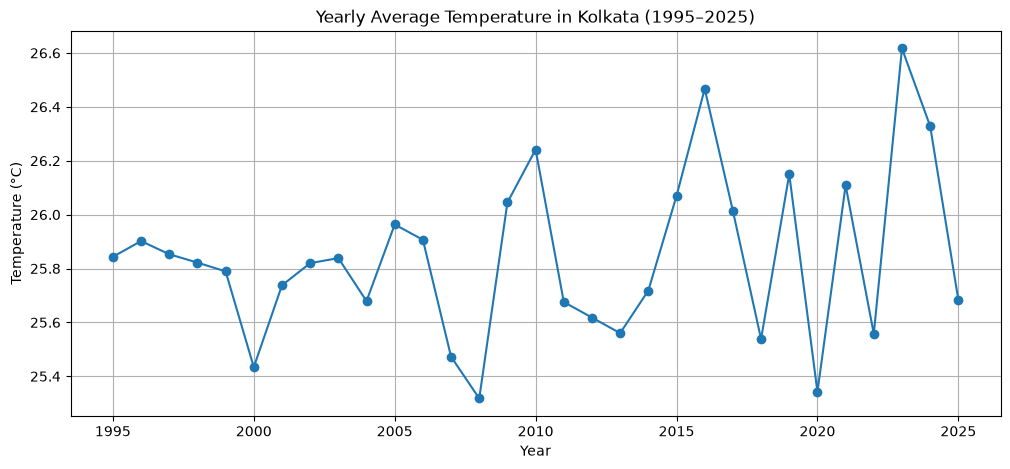

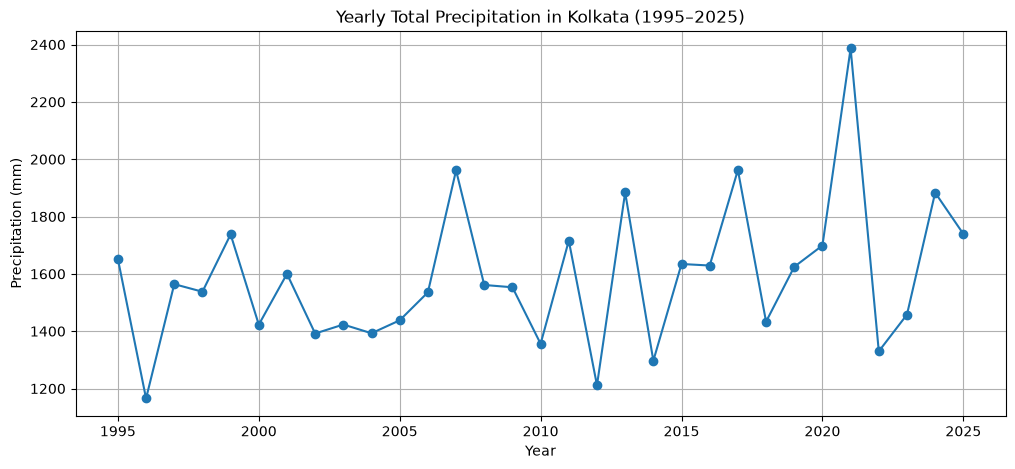

In [66]:

import matplotlib.pyplot as plt

# Group daily observations by year
yearly_data = climate_data.set_index("date").resample("YE").agg({
    "t2m_c": "mean",
    "t2m_max_c": "mean",
    "t2m_min_c": "mean",
    "precip_mm": "sum",
    "humidity_pct": "mean",
    "solar_mj": "mean",
    "wind_speed_ms": "mean"
})

# Use year as the index
yearly_data.index = yearly_data.index.year

# Plot yearly average temperature
plt.figure(figsize=(12, 5))
plt.plot(yearly_data.index, yearly_data["t2m_c"], marker="o")
plt.title("Yearly Average Temperature in Kolkata (1995–2025)")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()

# Plot yearly total precipitation
plt.figure(figsize=(12, 5))
plt.plot(yearly_data.index, yearly_data["precip_mm"], marker="o")
plt.title("Yearly Total Precipitation in Kolkata (1995–2025)")
plt.xlabel("Year")
plt.ylabel("Precipitation (mm)")
plt.grid(True)
plt.show()


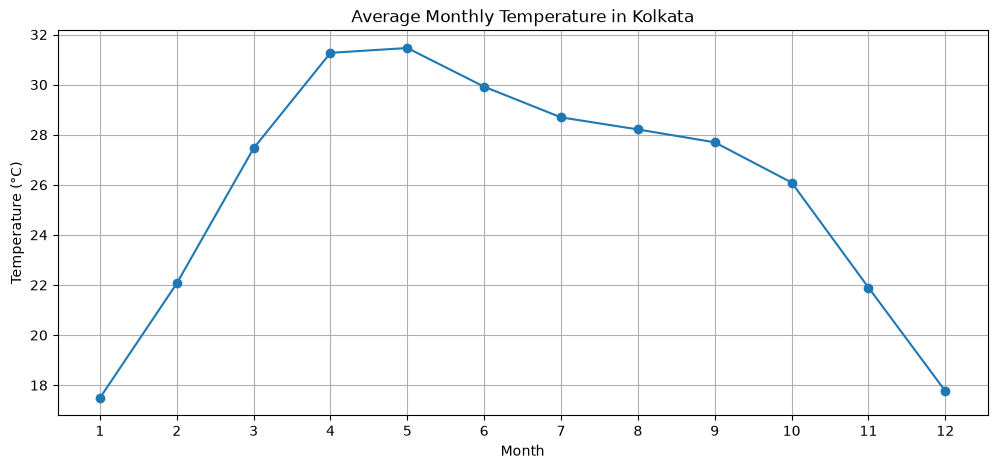

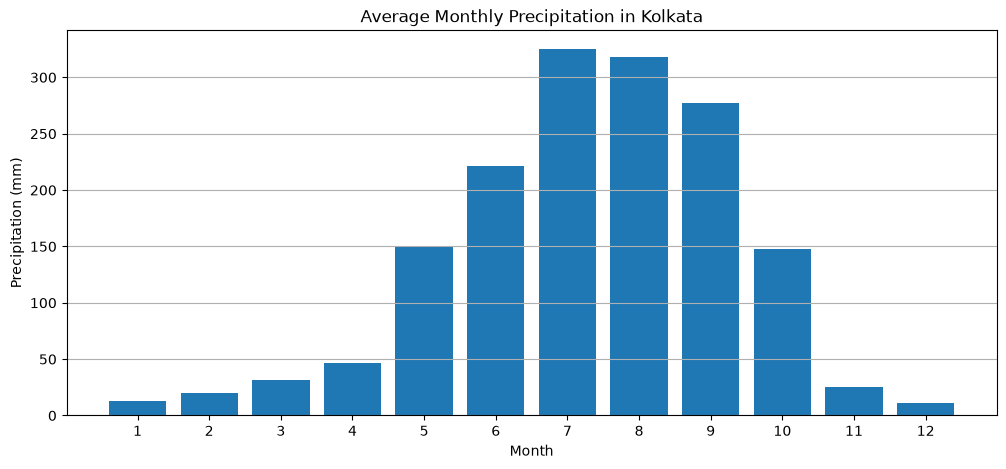

In [67]:

# Extract month and year
monthly_data = climate_data.copy()

monthly_data["year"] = monthly_data["date"].dt.year
monthly_data["month"] = monthly_data["date"].dt.month

# Calculate monthly statistics for each year
monthly_summary = monthly_data.groupby(
    ["year", "month"]
).agg({
    "t2m_c": "mean",
    "t2m_max_c": "mean",
    "t2m_min_c": "mean",
    "precip_mm": "sum",
    "humidity_pct": "mean",
    "solar_mj": "mean",
    "wind_speed_ms": "mean"
}).reset_index()

# Calculate average monthly climate across all years
monthly_climate = monthly_summary.groupby("month").mean(numeric_only=True)

# Plot monthly average temperature
plt.figure(figsize=(12, 5))
plt.plot(monthly_climate.index, monthly_climate["t2m_c"], marker="o")
plt.title("Average Monthly Temperature in Kolkata")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

# Plot average monthly total precipitation
plt.figure(figsize=(12, 5))
plt.bar(monthly_climate.index, monthly_climate["precip_mm"])
plt.title("Average Monthly Precipitation in Kolkata")
plt.xlabel("Month")
plt.ylabel("Precipitation (mm)")
plt.xticks(range(1, 13))
plt.grid(axis="y")
plt.show()


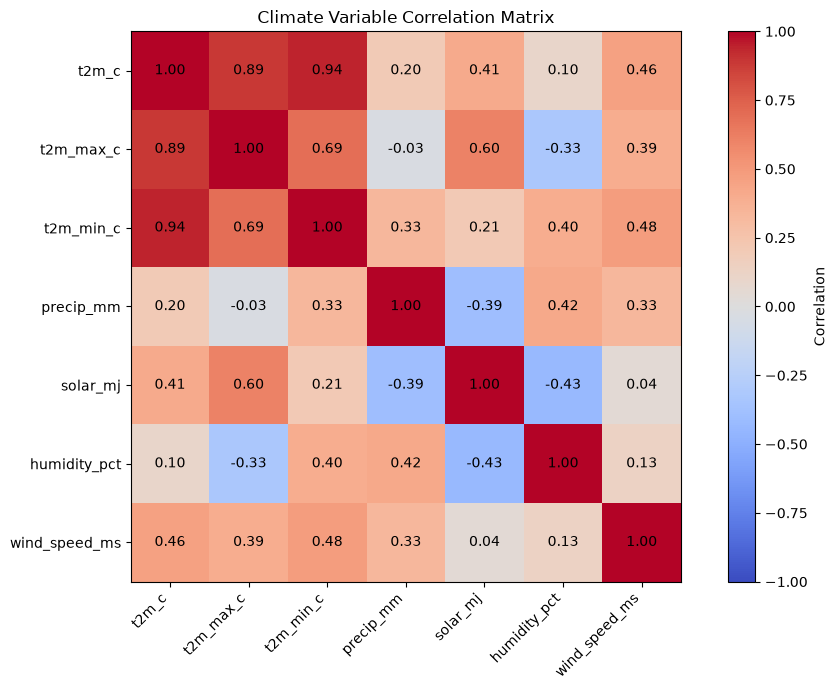

In [68]:

climate_variables = [
    "t2m_c",
    "t2m_max_c",
    "t2m_min_c",
    "precip_mm",
    "solar_mj",
    "humidity_pct",
    "wind_speed_ms"
]

correlation_matrix = climate_data[climate_variables].corr()

plt.figure(figsize=(10, 7))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(climate_variables)),
    climate_variables,
    rotation=45,
    ha="right"
)

plt.yticks(range(len(climate_variables)), climate_variables)

plt.title("Climate Variable Correlation Matrix")

for i in range(len(climate_variables)):
    for j in range(len(climate_variables)):
        plt.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()


## Seasonal Feature Engineering

The daily climate observations are aggregated into
Kharif, Rabi and Zaid seasonal records.

The resulting dataset will be used for climate
pattern identification using KMeans clustering.

In [69]:

# Create a copy of the original climate dataset
seasonal_data = climate_data.copy()

# Extract year and month
seasonal_data["year"] = seasonal_data["date"].dt.year
seasonal_data["month"] = seasonal_data["date"].dt.month

# Assign agricultural seasons
def assign_season(month):

    if month in [6, 7, 8, 9, 10]:
        return "Kharif"

    elif month in [11, 12, 1, 2]:
        return "Rabi"

    else:
        return "Zaid"


seasonal_data["season"] = seasonal_data["month"].apply(assign_season)

# Assign season year
# November and December belong to the following Rabi season year
seasonal_data["season_year"] = seasonal_data["year"]

rabi_mask = (
    (seasonal_data["season"] == "Rabi") &
    (seasonal_data["month"].isin([11, 12]))
)

seasonal_data.loc[rabi_mask, "season_year"] += 1

# Remove incomplete Rabi seasons at the dataset boundaries
seasonal_data = seasonal_data[
    ~(
        (seasonal_data["season"] == "Rabi") &
        (seasonal_data["season_year"].isin([1995, 2026]))
    )
].copy()

# Display season distribution
display(
    seasonal_data.groupby(
        ["season_year", "season"]
    ).size().unstack()
)


season,Kharif,Rabi,Zaid
season_year,,,
1995,153.0,NaN,92.0
1996,153.0,121.0,92.0
1997,153.0,120.0,92.0
1998,153.0,120.0,92.0
1999,153.0,120.0,92.0
2000,153.0,121.0,92.0
2001,153.0,120.0,92.0
2002,153.0,120.0,92.0
2003,153.0,120.0,92.0


In [71]:

# Define seasonal aggregation rules
aggregation_rules = {
    "t2m_c": "mean",
    "t2m_max_c": "mean",
    "t2m_min_c": "mean",
    "precip_mm": ["sum", "std", "max"],
    "solar_mj": "mean",
    "humidity_pct": "mean",
    "wind_speed_ms": "mean"
}

# Aggregate daily data into seasonal records
seasonal_features = seasonal_data.groupby(
    ["season_year", "season"]
).agg(aggregation_rules)

# Flatten the multi-level column names
seasonal_features.columns = [
    "_".join(col).strip("_")
    if isinstance(col, tuple)
    else col
    for col in seasonal_features.columns
]

# Calculate number of rainy days
rainy_days = seasonal_data.groupby(
    ["season_year", "season"]
)["precip_mm"].apply(lambda x: (x > 0).sum())

seasonal_features["rainy_days"] = rainy_days

# Rename columns for clarity
seasonal_features = seasonal_features.rename(columns={
    "t2m_c_mean": "avg_temperature",
    "t2m_max_c_mean": "avg_max_temperature",
    "t2m_min_c_mean": "avg_min_temperature",
    "precip_mm_sum": "total_rainfall",
    "precip_mm_std": "rainfall_std",
    "precip_mm_max": "max_daily_rainfall",
    "solar_mj_mean": "avg_solar_radiation",
    "humidity_pct_mean": "avg_humidity",
    "wind_speed_ms_mean": "avg_wind_speed"
})

# Display final seasonal features
display(seasonal_features.head(10))

print("Seasonal dataset shape:", seasonal_features.shape)


avg_temperature  avg_max_temperature  avg_min_temperature  \
season_year season                                                              
1995        Kharif        27.652092            30.581961            25.422876   
            Zaid          30.489783            38.311087            24.117065   
1996        Kharif        27.816667            31.418105            24.886405   
            Rabi          19.692066            26.817190            13.384215   
            Zaid          31.121739            39.389348            24.699348   
1997        Kharif        27.838889            31.065948            25.232157   
            Rabi          19.675333            27.775250            12.351083   
            Zaid          29.501196            36.738696            23.629783   
1998        Kharif        28.500261            31.636405            26.154248   
            Rabi          20.302250            27.098250            14.446083   

                    total_rainfall  rainfall_std  max_daily_rainfall  \
season_year season                                                     
1995        Kharif         1205.78     10.665959               79.91   
            Zaid            246.56      9.679514               69.74   
1996        Kharif         1070.93     10.455753               52.59   
            Rabi            181.46      8.409096               77.89   
            Zaid             70.55      2.323056               15.97   
1997        Kharif         1205.12      9.293049               37.31   
            Rabi             39.12      2.044607               20.13   
            Zaid            295.48      6.973186               38.37   
1998        Kharif         1058.77      8.608488               60.97   
            Rabi             96.24      2.536454               21.32   

                    avg_solar_radiation  avg_humidity  avg_wind_speed  \
season_year season                                                      
1995        Kharif            15.449477     87.915752        2.517255   
            Zaid              22.228043     55.613587        2.759891   
1996        Kharif            16.012680     83.541634        2.521961   
            Rabi              15.420744     69.527190        1.824876   
            Zaid              21.363152     55.526630        3.023043   
1997        Kharif            16.119673     85.069608        2.408170   
            Rabi              15.359917     55.782833        1.735000   
            Zaid              21.069674     63.030543        2.421848   
1998        Kharif            15.596144     86.062222        2.545817   
            Rabi              13.960500     68.712500        1.705583   

                    rainy_days  
season_year season              
1995        Kharif         142  
            Zaid            47  
1996        Kharif         134  
            Rabi            39  
            Zaid            40  
1997        Kharif         140  
            Rabi            18  
            Zaid            65  
1998        Kharif         145  
            Rabi            55

Seasonal dataset shape: (92, 10)


## Seasonal Feature Analysis

In [72]:
# Define the climate features
feature_columns = [
    "avg_temperature",
    "avg_max_temperature",
    "avg_min_temperature",
    "total_rainfall",
    "rainfall_std",
    "max_daily_rainfall",
    "avg_solar_radiation",
    "avg_humidity",
    "avg_wind_speed",
    "rainy_days"
]

# Extract only the climate features
X = seasonal_features[feature_columns].copy()

# Display dataset dimensions
print("Dataset shape:", X.shape)

# Check missing values
print("\nMissing values:")
print(X.isnull().sum())

# Check infinite values
import numpy as np

print("\nInfinite values:")
print(np.isinf(X).sum())

# Display statistical summary
print("\nStatistical summary:")
display(X.describe().T)

Dataset shape: (92, 10)

Missing values:
avg_temperature        0
avg_max_temperature    0
avg_min_temperature    0
total_rainfall         0
rainfall_std           0
max_daily_rainfall     0
avg_solar_radiation    0
avg_humidity           0
avg_wind_speed         0
rainy_days             0
dtype: int64

Infinite values:
avg_temperature        0
avg_max_temperature    0
avg_min_temperature    0
total_rainfall         0
rainfall_std           0
max_daily_rainfall     0
avg_solar_radiation    0
avg_humidity           0
avg_wind_speed         0
rainy_days             0
dtype: int64

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
avg_temperature,92.0,26.037056,4.510043,18.284667,20.197708,28.125817,29.564946,31.156522
avg_max_temperature,92.0,31.852973,4.462984,24.909667,27.170938,31.408627,36.674402,39.389348
avg_min_temperature,92.0,21.163520,5.389516,11.508500,14.128562,24.104891,25.286863,26.420719
total_rainfall,92.0,534.099130,564.630561,1.050000,91.355000,220.405000,1116.705000,1958.200000
rainfall_std,92.0,6.709359,4.471527,0.061720,3.119664,5.669066,10.281210,19.781506
max_daily_rainfall,92.0,45.891522,35.104370,0.660000,20.102500,36.200000,63.720000,171.860000
avg_solar_radiation,92.0,16.837961,2.735195,12.475124,14.854837,15.604412,19.792391,22.228043
avg_humidity,92.0,71.752465,11.258541,54.898370,63.036168,68.932655,84.963775,89.150261
avg_wind_speed,92.0,2.219866,0.473413,1.365372,1.664572,2.358325,2.566223,3.023043
rainy_days,92.0,74.315217,51.006125,6.000000,27.750000,60.000000,136.000000,150.000000


### Feature Correlation Analysis

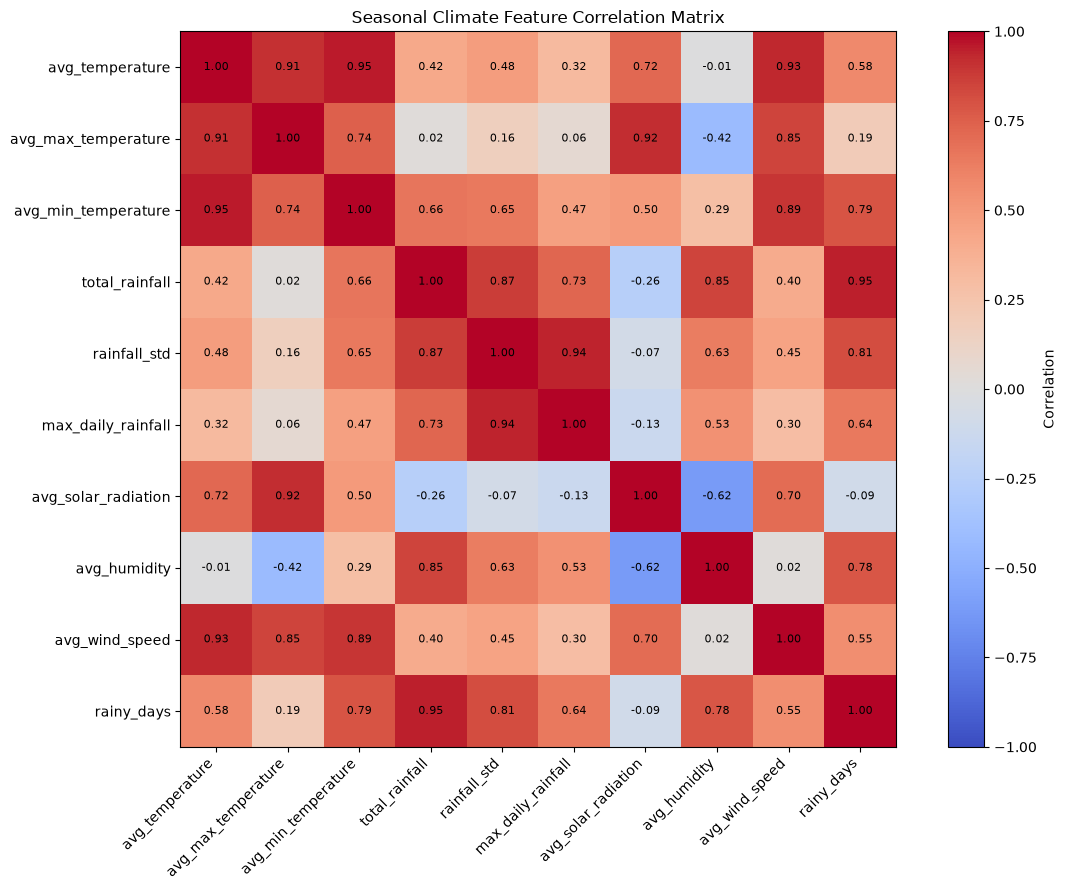

In [73]:
import matplotlib.pyplot as plt

correlation_matrix = X.corr()

plt.figure(figsize=(12, 9))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(feature_columns)),
    feature_columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(feature_columns)),
    feature_columns
)

plt.title("Seasonal Climate Feature Correlation Matrix")

for i in range(len(feature_columns)):
    for j in range(len(feature_columns)):
        plt.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()

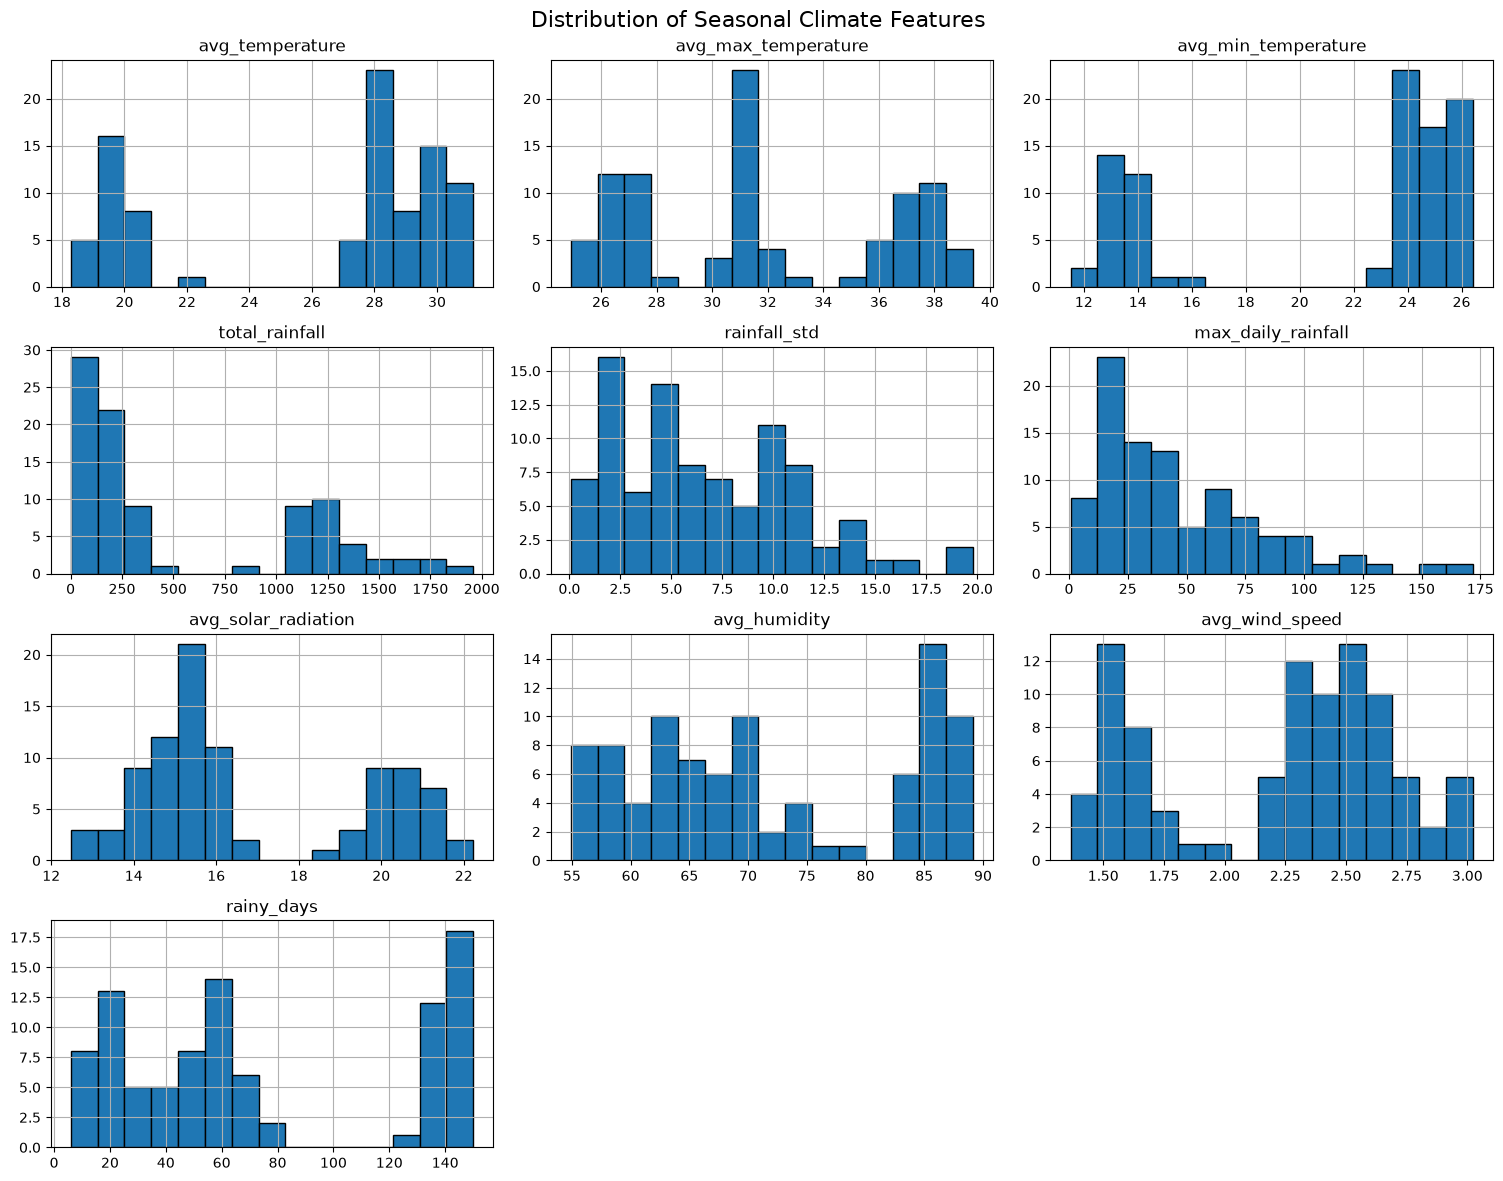

In [74]:
X.hist(
    figsize=(15, 12),
    bins=15,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Seasonal Climate Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [75]:
# Calculate the number of days in each seasonal record
season_days = seasonal_data.groupby(
    ["season_year", "season"]
).size()

seasonal_features["season_days"] = season_days

# Calculate average daily rainfall
seasonal_features["avg_daily_rainfall"] = (
    seasonal_features["total_rainfall"] /
    seasonal_features["season_days"]
)

# Calculate the proportion of rainy days
seasonal_features["rainy_day_ratio"] = (
    seasonal_features["rainy_days"] /
    seasonal_features["season_days"]
)

display(
    seasonal_features[
        [
            "season_days",
            "total_rainfall",
            "avg_daily_rainfall",
            "rainy_days",
            "rainy_day_ratio"
        ]
    ].head(10)
)

season_days  total_rainfall  avg_daily_rainfall  \
season_year season                                                    
1995        Kharif          153         1205.78            7.880915   
            Zaid             92          246.56            2.680000   
1996        Kharif          153         1070.93            6.999542   
            Rabi            121          181.46            1.499669   
            Zaid             92           70.55            0.766848   
1997        Kharif          153         1205.12            7.876601   
            Rabi            120           39.12            0.326000   
            Zaid             92          295.48            3.211739   
1998        Kharif          153         1058.77            6.920065   
            Rabi            120           96.24            0.802000   

                    rainy_days  rainy_day_ratio  
season_year season                               
1995        Kharif         142         0.928105  
            Zaid            47         0.510870  
1996        Kharif         134         0.875817  
            Rabi            39         0.322314  
            Zaid            40         0.434783  
1997        Kharif         140         0.915033  
            Rabi            18         0.150000  
            Zaid            65         0.706522  
1998        Kharif         145         0.947712  
            Rabi            55         0.458333

In [76]:
# Compare average climate conditions across agricultural seasons
season_comparison = seasonal_features.groupby(
    level="season"
)[
    [
        "avg_temperature",
        "total_rainfall",
        "avg_daily_rainfall",
        "rainfall_std",
        "avg_solar_radiation",
        "avg_humidity",
        "avg_wind_speed",
        "rainy_day_ratio"
    ]
].mean()

display(season_comparison.round(2))

,avg_temperature,total_rainfall,avg_daily_rainfall,rainfall_std,avg_solar_radiation,avg_humidity,avg_wind_speed,rainy_day_ratio
season,,,,,,,,
Kharif,28.11,1289.72,8.43,11.40,15.51,85.94,2.44,0.92
Rabi,19.74,69.89,0.58,2.88,14.48,68.84,1.59,0.18
Zaid,30.05,227.71,2.48,5.72,20.45,60.39,2.61,0.63


In [77]:
# Select features for climate clustering

CLUSTER_FEATURES = [
    "avg_temperature",
    "total_rainfall",
    "rainfall_std",
    "avg_solar_radiation",
    "avg_humidity",
    "avg_wind_speed",
    "rainy_day_ratio"
]

# Create the feature dataset
X = seasonal_features[CLUSTER_FEATURES].copy()

display(X.head())

print("Selected feature shape:", X.shape)

avg_temperature  total_rainfall  rainfall_std  \
season_year season                                                  
1995        Kharif        27.652092         1205.78     10.665959   
            Zaid          30.489783          246.56      9.679514   
1996        Kharif        27.816667         1070.93     10.455753   
            Rabi          19.692066          181.46      8.409096   
            Zaid          31.121739           70.55      2.323056   

                    avg_solar_radiation  avg_humidity  avg_wind_speed  \
season_year season                                                      
1995        Kharif            15.449477     87.915752        2.517255   
            Zaid              22.228043     55.613587        2.759891   
1996        Kharif            16.012680     83.541634        2.521961   
            Rabi              15.420744     69.527190        1.824876   
            Zaid              21.363152     55.526630        3.023043   

                    rainy_day_ratio  
season_year season                   
1995        Kharif         0.928105  
            Zaid           0.510870  
1996        Kharif         0.875817  
            Rabi           0.322314  
            Zaid           0.434783

Selected feature shape: (92, 7)


# features scaling

In [78]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Create the scaler
scaler = StandardScaler()

# Fit the scaler and transform the selected features
scaled_features = scaler.fit_transform(X)

# Convert the scaled data back into a DataFrame
scaled_df = pd.DataFrame(
    scaled_features,
    columns=CLUSTER_FEATURES,
    index=X.index
)

display(scaled_df.head())

avg_temperature  total_rainfall  rainfall_std  \
season_year season                                                  
1995        Kharif         0.360060        1.196112      0.889692   
            Zaid           0.992701       -0.512042      0.667877   
1996        Kharif         0.396751        0.955975      0.842424   
            Rabi          -1.414567       -0.627971      0.382207   
            Zaid           1.133591       -0.825476     -0.986316   

                    avg_solar_radiation  avg_humidity  avg_wind_speed  \
season_year season                                                      
1995        Kharif            -0.510418      1.443513        0.631622   
            Zaid               1.981438     -1.441333        1.146957   
1996        Kharif            -0.303380      1.052869        0.641617   
            Rabi              -0.520980     -0.198735       -0.838918   
            Zaid               1.663497     -1.449099        1.705865   

                    rainy_day_ratio  
season_year season                   
1995        Kharif         1.097053  
            Zaid          -0.229998  
1996        Kharif         0.930748  
            Rabi          -0.829715  
            Zaid          -0.471999

# KMeans Clustering

## Finding the value of K

In [79]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test different numbers of clusters
k_values = range(2, 8)

inertia_scores = []
silhouette_scores = []

for k in k_values:

    # Create the K-Means model
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Train the model
    labels = kmeans.fit_predict(scaled_df)

    # Store evaluation scores
    inertia_scores.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(scaled_df, labels)
    )

# Display the results
for k, inertia, silhouette in zip(
    k_values,
    inertia_scores,
    silhouette_scores
):
    print(
        f"K={k} | "
        f"Inertia={inertia:.2f} | "
        f"Silhouette Score={silhouette:.4f}"
    )

K=2 | Inertia=305.54 | Silhouette Score=0.5404
K=3 | Inertia=74.50 | Silhouette Score=0.7157
K=4 | Inertia=61.16 | Silhouette Score=0.6220
K=5 | Inertia=54.01 | Silhouette Score=0.4621
K=6 | Inertia=47.11 | Silhouette Score=0.4611
K=7 | Inertia=42.09 | Silhouette Score=0.3952


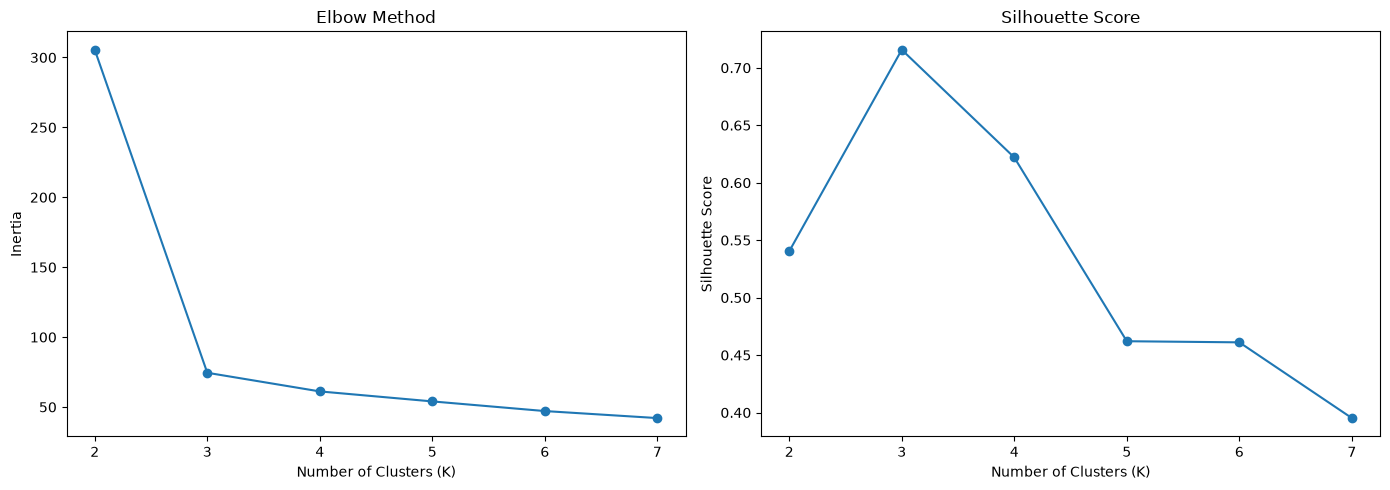

In [80]:
import matplotlib.pyplot as plt

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow method
axes[0].plot(
    list(k_values),
    inertia_scores,
    marker="o"
)

axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

# Silhouette scores
axes[1].plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [81]:
# Create and train the final K-Means model
final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Assign cluster labels
seasonal_features["cluster"] = final_kmeans.fit_predict(scaled_df)

# Calculate average feature values for each cluster
cluster_profiles = seasonal_features.groupby("cluster")[
    CLUSTER_FEATURES
].mean().round(2)

# Count observations in each cluster
cluster_counts = seasonal_features["cluster"].value_counts().sort_index()

print("Cluster profiles:")
display(cluster_profiles)

print("Number of observations in each cluster:")
display(cluster_counts)

Cluster profiles:


,avg_temperature,total_rainfall,rainfall_std,avg_solar_radiation,avg_humidity,avg_wind_speed,rainy_day_ratio
cluster,,,,,,,
0,30.05,227.71,5.72,20.45,60.39,2.61,0.63
1,19.74,69.89,2.88,14.48,68.84,1.59,0.18
2,28.11,1289.72,11.40,15.51,85.94,2.44,0.92


Number of observations in each cluster:


cluster
0    31
1    30
2    31
Name: count, dtype: int64

In [82]:
# Compare K-Means clusters with actual agricultural seasons

cluster_season_comparison = pd.crosstab(
    seasonal_features["cluster"],
    seasonal_features.index.get_level_values("season")
)

display(cluster_season_comparison)

col_0,Kharif,Rabi,Zaid
cluster,,,
0,0,0,31
1,0,30,0
2,31,0,0


## Isolation Forest – Climate Anomaly Detection

In [83]:
from ml.pipeline.anomaly_detection import train_anomaly_model

ANOMALY_FEATURES = [
    "avg_temperature",
    "total_rainfall",
    "rainfall_std",
    "avg_solar_radiation",
    "avg_humidity",
    "avg_wind_speed",
    "rainy_day_ratio"
]

isolation_model, anomaly_results = train_anomaly_model(
    seasonal_features,
    ANOMALY_FEATURES
)

display(anomaly_results.head())

avg_temperature  avg_max_temperature  avg_min_temperature  \
season_year season                                                              
1995        Kharif        27.652092            30.581961            25.422876   
            Zaid          30.489783            38.311087            24.117065   
1996        Kharif        27.816667            31.418105            24.886405   
            Rabi          19.692066            26.817190            13.384215   
            Zaid          31.121739            39.389348            24.699348   

                    total_rainfall  rainfall_std  max_daily_rainfall  \
season_year season                                                     
1995        Kharif         1205.78     10.665959               79.91   
            Zaid            246.56      9.679514               69.74   
1996        Kharif         1070.93     10.455753               52.59   
            Rabi            181.46      8.409096               77.89   
            Zaid             70.55      2.323056               15.97   

                    avg_solar_radiation  avg_humidity  avg_wind_speed  \
season_year season                                                      
1995        Kharif            15.449477     87.915752        2.517255   
            Zaid              22.228043     55.613587        2.759891   
1996        Kharif            16.012680     83.541634        2.521961   
            Rabi              15.420744     69.527190        1.824876   
            Zaid              21.363152     55.526630        3.023043   

                    rainy_days  season_days  avg_daily_rainfall  \
season_year season                                                
1995        Kharif         142          153            7.880915   
            Zaid            47           92            2.680000   
1996        Kharif         134          153            6.999542   
            Rabi            39          121            1.499669   
            Zaid            40           92            0.766848   

                    rainy_day_ratio  cluster  anomaly  anomaly_score  
season_year season                                                    
1995        Kharif         0.928105        2        1       0.442190  
            Zaid           0.510870        0       -1       0.552311  
1996        Kharif         0.875817        2        1       0.455601  
            Rabi           0.322314        1       -1       0.545001  
            Zaid           0.434783        0       -1       0.583629

In [84]:
# Convert the index into regular columns
anomaly_summary = anomaly_results.reset_index()

# Select only observations classified as anomalies
detected_anomalies = anomaly_summary[
    anomaly_summary["anomaly"] == -1
]

# Sort by anomaly score (most unusual first)
detected_anomalies = detected_anomalies.sort_values(
    by="anomaly_score",
    ascending=False
)

print("Total observations:", len(anomaly_results))
print("Detected anomalies:", len(detected_anomalies))
print(
    "Normal observations:",
    (anomaly_results["anomaly"] == 1).sum()
)

display(
    detected_anomalies[
        [
            "season_year",
            "season",
            "avg_temperature",
            "total_rainfall",
            "avg_humidity",
            "rainy_day_ratio",
            "anomaly_score"
        ]
    ]
)

Total observations: 92
Detected anomalies: 23
Normal observations: 69


,season_year,season,avg_temperature,total_rainfall,avg_humidity,rainy_day_ratio,anomaly_score
77,2021,Kharif,28.018627,1958.20,88.403660,0.980392,0.606932
76,2020,Zaid,28.610761,438.95,66.093913,0.826087,0.594030
4,1996,Zaid,31.121739,70.55,55.526630,0.434783,0.583629
75,2020,Rabi,19.023058,182.67,75.888760,0.272727,0.581612
81,2022,Rabi,19.320917,193.53,78.748583,0.383333,0.578160
63,2016,Rabi,21.909256,91.04,64.708595,0.231405,0.564547
35,2007,Kharif,27.821438,1738.78,86.951569,0.921569,0.560880
1,1995,Zaid,30.489783,246.56,55.613587,0.510870,0.552311
88,2024,Zaid,30.807065,312.01,56.256848,0.652174,0.549024
3,1996,Rabi,19.692066,181.46,69.527190,0.322314,0.545001


In [85]:
# Count normal and anomalous observations by season
season_anomaly_summary = pd.crosstab(
    anomaly_summary["season"],
    anomaly_summary["anomaly"]
)

season_anomaly_summary = season_anomaly_summary.rename(
    columns={
        -1: "Anomalies",
        1: "Normal"
    }
)

season_anomaly_summary["Total"] = (
    season_anomaly_summary["Anomalies"]
    + season_anomaly_summary["Normal"]
)

season_anomaly_summary["Anomaly_Percentage"] = (
    season_anomaly_summary["Anomalies"]
    / season_anomaly_summary["Total"]
    * 100
)

display(season_anomaly_summary.round(2))

anomaly,Anomalies,Normal,Total,Anomaly_Percentage
season,,,,
Kharif,5,26,31,16.13
Rabi,11,19,30,36.67
Zaid,7,24,31,22.58


In [87]:
seasonal_data = seasonal_features.reset_index()

Season-wise Climate Anomaly Detection

In [88]:
from sklearn.ensemble import IsolationForest

# Convert the MultiIndex into regular columns
seasonal_data = seasonal_features.reset_index()

# Store results from all three seasons
seasonal_anomaly_results = []

# Process each agricultural season separately
for season in seasonal_data["season"].unique():

    # Select observations belonging to this season
    season_data = seasonal_data[
        seasonal_data["season"] == season
    ].copy()

    # Select climate features
    X = season_data[ANOMALY_FEATURES].copy()

    # Create and train a separate Isolation Forest
    model = IsolationForest(
        n_estimators=200,
        contamination="auto",
        random_state=42
    )

    model.fit(X)

    # Predict anomalies
    predictions = model.predict(X)

    # Calculate anomaly scores
    scores = -model.score_samples(X)

    # Store predictions and scores
    season_data["anomaly"] = predictions
    season_data["anomaly_score"] = scores

    seasonal_anomaly_results.append(season_data)


# Combine results from all seasons
seasonal_anomaly_results = pd.concat(
    seasonal_anomaly_results,
    ignore_index=True
)

display(seasonal_anomaly_results.head())

,season_year,season,avg_temperature,avg_max_temperature,avg_min_temperature,total_rainfall,rainfall_std,max_daily_rainfall,avg_solar_radiation,avg_humidity,avg_wind_speed,rainy_days,season_days,avg_daily_rainfall,rainy_day_ratio,cluster,anomaly,anomaly_score
0,1995,Kharif,27.652092,30.581961,25.422876,1205.78,10.665959,79.91,15.449477,87.915752,2.517255,142,153,7.880915,0.928105,2,1,0.430683
1,1996,Kharif,27.816667,31.418105,24.886405,1070.93,10.455753,52.59,16.012680,83.541634,2.521961,134,153,6.999542,0.875817,2,1,0.471763
2,1997,Kharif,27.838889,31.065948,25.232157,1205.12,9.293049,37.31,16.119673,85.069608,2.408170,140,153,7.876601,0.915033,2,1,0.436109
3,1998,Kharif,28.500261,31.636405,26.154248,1058.77,8.608488,60.97,15.596144,86.062222,2.545817,145,153,6.920065,0.947712,2,1,0.446730
4,1999,Kharif,27.747516,30.761830,25.475556,1615.32,12.817194,80.34,14.976863,87.650000,2.581699,146,153,10.557647,0.954248,2,1,0.493701


In [89]:
seasonal_comparison = pd.crosstab(
    seasonal_anomaly_results["season"],
    seasonal_anomaly_results["anomaly"]
)

seasonal_comparison = seasonal_comparison.rename(
    columns={
        -1: "Anomalies",
        1: "Normal"
    }
)

seasonal_comparison["Total"] = (
    seasonal_comparison["Anomalies"]
    + seasonal_comparison["Normal"]
)

seasonal_comparison["Anomaly_Percentage"] = (
    seasonal_comparison["Anomalies"]
    / seasonal_comparison["Total"]
) * 100

display(seasonal_comparison.round(2))

anomaly,Anomalies,Normal,Total,Anomaly_Percentage
season,,,,
Kharif,8,23,31,25.81
Rabi,10,20,30,33.33
Zaid,8,23,31,25.81


In [91]:
import importlib
import ml.pipeline.anomaly_detection as anomaly_detection

importlib.reload(anomaly_detection)

<module 'ml.pipeline.anomaly_detection' from 'C:\\roktim_files\\myfiles\\work\\python\\nasa-prac\\backend\\ml\\pipeline\\anomaly_detection.py'>

In [94]:
print("Index names:", seasonal_features.index.names)
print("Columns:", seasonal_features.columns.tolist())

Index names: ['season_year', 'season']
Columns: ['avg_temperature', 'avg_max_temperature', 'avg_min_temperature', 'total_rainfall', 'rainfall_std', 'max_daily_rainfall', 'avg_solar_radiation', 'avg_humidity', 'avg_wind_speed', 'rainy_days', 'season_days', 'avg_daily_rainfall', 'rainy_day_ratio', 'cluster']


In [95]:
seasonal_features = seasonal_features.reset_index()

In [96]:
anomaly_results = anomaly_detection.train_seasonal_anomaly_models(
    seasonal_features,
    ANOMALY_FEATURES
)

display(anomaly_results.head())

,season_year,season,avg_temperature,avg_max_temperature,avg_min_temperature,total_rainfall,rainfall_std,max_daily_rainfall,avg_solar_radiation,avg_humidity,avg_wind_speed,rainy_days,season_days,avg_daily_rainfall,rainy_day_ratio,cluster,anomaly,anomaly_score
0,1995,Kharif,27.652092,30.581961,25.422876,1205.78,10.665959,79.91,15.449477,87.915752,2.517255,142,153,7.880915,0.928105,2,1,0.430683
1,1996,Kharif,27.816667,31.418105,24.886405,1070.93,10.455753,52.59,16.012680,83.541634,2.521961,134,153,6.999542,0.875817,2,1,0.471763
2,1997,Kharif,27.838889,31.065948,25.232157,1205.12,9.293049,37.31,16.119673,85.069608,2.408170,140,153,7.876601,0.915033,2,1,0.436109
3,1998,Kharif,28.500261,31.636405,26.154248,1058.77,8.608488,60.97,15.596144,86.062222,2.545817,145,153,6.920065,0.947712,2,1,0.446730
4,1999,Kharif,27.747516,30.761830,25.475556,1615.32,12.817194,80.34,14.976863,87.650000,2.581699,146,153,10.557647,0.954248,2,1,0.493701


In [97]:
import importlib
import ml.pipeline.anomaly_detection as anomaly_detection

importlib.reload(anomaly_detection)

<module 'ml.pipeline.anomaly_detection' from 'C:\\roktim_files\\myfiles\\work\\python\\nasa-prac\\backend\\ml\\pipeline\\anomaly_detection.py'>

In [98]:
# Select one observation from each season
test_data = seasonal_features.groupby(
    "season",
    group_keys=False
).tail(1).copy()

# Run anomaly prediction
prediction_results = anomaly_detection.predict_climate_anomalies(
    test_data,
    ANOMALY_FEATURES
)

display(
    prediction_results[
        ["season", "anomaly", "anomaly_score"]
    ]
)

,season,anomaly,anomaly_score
89,Kharif,-1,0.522974
90,Rabi,1,0.446916
91,Zaid,1,0.464957


In [101]:
import joblib
from pathlib import Path

# Locate the models directory
MODEL_DIR = Path.cwd().parent / "models"

# Create the directory if it doesn't exist
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the newly trained K-Means model
joblib.dump(
    kmeans,
    MODEL_DIR / "kmeans_model.pkl"
)

# Save the newly trained Feature Scaler
joblib.dump(
    scaler,
    MODEL_DIR / "feature_scaler.pkl"
)

print("New K-Means model and scaler saved successfully!")

New K-Means model and scaler saved successfully!


In [103]:
if "rainy_day_ratio" in seasonal_features.columns:
    print("rainy_day_ratio exists!")
else:
    print("rainy_day_ratio does not exist.")

rainy_day_ratio exists!


In [104]:
from ml.pipeline.climate_memory import (
    save_climate_memory,
    load_climate_memory
)

# Save your existing seasonal dataset
memory = save_climate_memory(seasonal_features)

print("Climate Memory saved successfully!")

# Load the saved data
historical_data = load_climate_memory()

display(historical_data.head())

print("Total historical records:", len(historical_data))

Climate Memory saved successfully!


,season_year,season,avg_temperature,avg_max_temperature,avg_min_temperature,total_rainfall,rainfall_std,max_daily_rainfall,avg_solar_radiation,avg_humidity,avg_wind_speed,rainy_days,season_days,avg_daily_rainfall,rainy_day_ratio,cluster
0,1995,Kharif,27.652092,30.581961,25.422876,1205.78,10.665959,79.91,15.449477,87.915752,2.517255,142,153,7.880915,0.928105,2
1,1995,Zaid,30.489783,38.311087,24.117065,246.56,9.679514,69.74,22.228043,55.613587,2.759891,47,92,2.680000,0.510870,0
2,1996,Kharif,27.816667,31.418105,24.886405,1070.93,10.455753,52.59,16.012680,83.541634,2.521961,134,153,6.999542,0.875817,2
3,1996,Rabi,19.692066,26.817190,13.384215,181.46,8.409096,77.89,15.420744,69.527190,1.824876,39,121,1.499669,0.322314,1
4,1996,Zaid,31.121739,39.389348,24.699348,70.55,2.323056,15.97,21.363152,55.526630,3.023043,40,92,0.766848,0.434783,0


Total historical records: 92


In [106]:
import importlib
import ml.pipeline.climate_memory as climate_memory

importlib.reload(climate_memory)

print("Module reloaded successfully!")
print(hasattr(climate_memory, "get_historical_baseline"))
print(hasattr(climate_memory, "get_similar_seasons"))

Module reloaded successfully!
True
True


In [107]:
from ml.pipeline.climate_memory import (
    get_historical_baseline,
    get_similar_seasons
)

# Test historical rainfall baseline
baseline = get_historical_baseline(
    season="Kharif",
    current_year=2026
)

print(baseline)

# Test similar historical seasons
similar = get_similar_seasons(
    cluster_id=2,
    exclude_year=2026
)

display(similar.head())

print("Similar historical observations:", len(similar))

{'season': 'Kharif', 'years_compared': 31, 'historical_avg_mm': 1289.72}


,season_year,season,avg_temperature,avg_max_temperature,avg_min_temperature,total_rainfall,rainfall_std,max_daily_rainfall,avg_solar_radiation,avg_humidity,avg_wind_speed,rainy_days,season_days,avg_daily_rainfall,rainy_day_ratio,cluster
0,1995,Kharif,27.652092,30.581961,25.422876,1205.78,10.665959,79.91,15.449477,87.915752,2.517255,142,153,7.880915,0.928105,2
2,1996,Kharif,27.816667,31.418105,24.886405,1070.93,10.455753,52.59,16.012680,83.541634,2.521961,134,153,6.999542,0.875817,2
5,1997,Kharif,27.838889,31.065948,25.232157,1205.12,9.293049,37.31,16.119673,85.069608,2.408170,140,153,7.876601,0.915033,2
8,1998,Kharif,28.500261,31.636405,26.154248,1058.77,8.608488,60.97,15.596144,86.062222,2.545817,145,153,6.920065,0.947712,2
11,1999,Kharif,27.747516,30.761830,25.475556,1615.32,12.817194,80.34,14.976863,87.650000,2.581699,146,153,10.557647,0.954248,2


Similar historical observations: 31


In [108]:
from ml.main import validate_climate_input

# Use one existing seasonal observation for testing
test_input = seasonal_features[
    seasonal_features["season_year"] == 2025
].iloc[[0]].copy()

result = validate_climate_input(test_input)

print("Input validation:", result)
display(test_input)

Input validation: True


,season_year,season,avg_temperature,avg_max_temperature,avg_min_temperature,total_rainfall,rainfall_std,max_daily_rainfall,avg_solar_radiation,avg_humidity,avg_wind_speed,rainy_days,season_days,avg_daily_rainfall,rainy_day_ratio,cluster
89,2025,Kharif,28.240523,31.392484,25.721634,1454.57,10.225705,54.48,14.601307,86.624314,2.202549,143,153,9.506993,0.934641,2


In [110]:
import joblib
from pathlib import Path

from ml.pipeline.clustering import FEATURE_COLUMNS

MODEL_DIR = Path.cwd().parent / "models"

scaler = joblib.load(MODEL_DIR / "feature_scaler.pkl")

print("FEATURE_COLUMNS currently used in clustering.py:")
print(FEATURE_COLUMNS)

print("\nFeatures the saved scaler was trained with:")
print(list(scaler.feature_names_in_))

print("\nNumber of features expected:", scaler.n_features_in_)
print("Number of features supplied:", len(FEATURE_COLUMNS))

FEATURE_COLUMNS currently used in clustering.py:
['total_rainfall', 'avg_temperature', 'rainfall_std', 'max_daily_rainfall', 'rainy_days', 'avg_max_temperature']

Features the saved scaler was trained with:
['avg_temperature', 'total_rainfall', 'rainfall_std', 'avg_solar_radiation', 'avg_humidity', 'avg_wind_speed', 'rainy_day_ratio']

Number of features expected: 7
Number of features supplied: 6


In [111]:
import joblib

print("Scaler expects:", scaler.n_features_in_)

kmeans = joblib.load(MODEL_DIR / "kmeans_model.pkl")

print("K-Means expects:", kmeans.n_features_in_)

Scaler expects: 7
K-Means expects: 7


In [113]:
import importlib
import ml.pipeline.clustering as clustering
import ml.main as main

importlib.reload(clustering)
importlib.reload(main)

cluster_analysis = main.get_cluster_analysis(test_input)

print("Season clusters:")
print(cluster_analysis["season_clusters"])

print("\nCurrent season:")
print(cluster_analysis["current_season"])

Season clusters:
[{'cluster_id': 0, 'label': 'Zaid-like', 'size': 31, 'centroid': {'avg_temperature': 28.09942265795207, 'total_rainfall': 1474.273333333333, 'rainfall_std': 13.592593331210566, 'avg_solar_radiation': 15.194193899782135, 'avg_humidity': 86.58333333333333, 'avg_wind_speed': 2.4361220043572986, 'rainy_day_ratio': 0.9270152505446623}, 'features': ['avg_temperature', 'total_rainfall', 'rainfall_std', 'avg_solar_radiation', 'avg_humidity', 'avg_wind_speed', 'rainy_day_ratio']}, {'cluster_id': 1, 'label': 'Rabi-like', 'size': 30, 'centroid': {'avg_temperature': 19.83733803449515, 'total_rainfall': 46.58913043478253, 'rainfall_std': 1.7688597055379045, 'avg_solar_radiation': 14.452942627859624, 'avg_humidity': 68.16116960114984, 'avg_wind_speed': 1.580020990537789, 'rainy_day_ratio': 0.16734339441849322}, 'features': ['avg_temperature', 'total_rainfall', 'rainfall_std', 'avg_solar_radiation', 'avg_humidity', 'avg_wind_speed', 'rainy_day_ratio']}, {'cluster_id': 2, 'label': 'Kh

c:\roktim_files\myfiles\work\python\nasa-prac\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


In [114]:
import joblib
from pathlib import Path

MODEL_DIR = Path.cwd().parent / "models"

kmeans = joblib.load(MODEL_DIR / "kmeans_model.pkl")
historical_data = main.load_climate_memory()

print("Number of clusters in saved K-Means:", kmeans.n_clusters)

print("\nCluster IDs in Climate Memory:")
print(sorted(historical_data["cluster"].dropna().unique()))

print("\nHistorical cluster distribution:")
print(historical_data["cluster"].value_counts().sort_index())

Number of clusters in saved K-Means: 7

Cluster IDs in Climate Memory:
[np.int64(0), np.int64(1), np.int64(2)]

Historical cluster distribution:
cluster
0    31
1    30
2    31
Name: count, dtype: int64


In [115]:
import joblib
import pandas as pd
from pathlib import Path

MODEL_DIR = Path.cwd().parent / "models"

# Load the current saved models
scaler = joblib.load(MODEL_DIR / "feature_scaler.pkl")
kmeans = joblib.load(MODEL_DIR / "kmeans_model.pkl")

# Load Climate Memory
historical_data = main.load_climate_memory()

# Extract the exact features used by K-Means
X_history = historical_data[clustering.FEATURE_COLUMNS].copy()

# Scale historical observations
X_history_scaled = pd.DataFrame(
    scaler.transform(X_history),
    columns=clustering.FEATURE_COLUMNS,
    index=X_history.index
)

# Reassign clusters using the current K-Means model
historical_data["cluster"] = kmeans.predict(
    X_history_scaled
)

# Check the updated distribution
print("Updated cluster distribution:")
print(
    historical_data["cluster"]
    .value_counts()
    .sort_index()
)

print("\nTotal historical observations:", len(historical_data))

Updated cluster distribution:
cluster
0     6
1    23
2    28
3    22
4     7
5     3
6     3
Name: count, dtype: int64

Total historical observations: 92


In [116]:
import joblib
from pathlib import Path
from ml.pipeline import clustering

MODEL_DIR = Path.cwd().parent / "models"

scaler = joblib.load(MODEL_DIR / "feature_scaler.pkl")
kmeans = joblib.load(MODEL_DIR / "kmeans_model.pkl")

print("Features in clustering.py:")
print(clustering.FEATURE_COLUMNS)

print("\nFeatures used to train scaler:")
print(list(scaler.feature_names_in_))

print("\nFeatures expected by K-Means:")
print(kmeans.n_features_in_)

print("\nNumber of K-Means clusters:")
print(kmeans.n_clusters)

Features in clustering.py:
['avg_temperature', 'total_rainfall', 'rainfall_std', 'avg_solar_radiation', 'avg_humidity', 'avg_wind_speed', 'rainy_day_ratio']

Features used to train scaler:
['avg_temperature', 'total_rainfall', 'rainfall_std', 'avg_solar_radiation', 'avg_humidity', 'avg_wind_speed', 'rainy_day_ratio']

Features expected by K-Means:
7

Number of K-Means clusters:
7


In [117]:
import joblib
from pathlib import Path

MODEL_DIR = Path.cwd().parent / "models"

kmeans = joblib.load(MODEL_DIR / "kmeans_model.pkl")
scaler = joblib.load(MODEL_DIR / "feature_scaler.pkl")

print("Number of clusters:", kmeans.n_clusters)
print("Scaler features:", list(scaler.feature_names_in_))
print("K-Means features:", kmeans.n_features_in_)

Number of clusters: 7
Scaler features: ['avg_temperature', 'total_rainfall', 'rainfall_std', 'avg_solar_radiation', 'avg_humidity', 'avg_wind_speed', 'rainy_day_ratio']
K-Means features: 7


In [118]:
from ml.pipeline.clustering import train_climate_clusters

# Train using the final seasonal dataset with 3 clusters
clustered_data = train_climate_clusters(
    seasonal_features,
    n_clusters=3
)

print("Cluster distribution:")
print(clustered_data["cluster"].value_counts().sort_index())

Cluster distribution:
cluster
0    31
1    30
2    31
Name: count, dtype: int64


In [119]:
import joblib
from pathlib import Path

MODEL_DIR = Path.cwd().parent / "models"

kmeans = joblib.load(MODEL_DIR / "kmeans_model.pkl")
scaler = joblib.load(MODEL_DIR / "feature_scaler.pkl")

print("Number of clusters:", kmeans.n_clusters)
print("Scaler features:", list(scaler.feature_names_in_))

Number of clusters: 3
Scaler features: ['avg_temperature', 'total_rainfall', 'rainfall_std', 'avg_solar_radiation', 'avg_humidity', 'avg_wind_speed', 'rainy_day_ratio']


In [120]:
import importlib
import ml.main as main

importlib.reload(main)

# Load historical Climate Memory
historical_data = main.load_climate_memory()

# Reassign clusters using the updated model
historical_data["cluster"] = main.predict_climate_cluster(
    historical_data
)

# Save updated Climate Memory
from ml.pipeline.climate_memory import save_climate_memory

save_climate_memory(historical_data)

print("Updated cluster distribution:")
print(historical_data["cluster"].value_counts().sort_index())

print("Total historical records:", len(historical_data))

Updated cluster distribution:
cluster
0    31
1    30
2    31
Name: count, dtype: int64
Total historical records: 92


In [121]:
import joblib
from pathlib import Path

MODEL_DIR = Path.cwd().parent / "models"

scaler = joblib.load(MODEL_DIR / "feature_scaler.pkl")
kmeans = joblib.load(MODEL_DIR / "kmeans_model.pkl")

print("Model directory:", MODEL_DIR.resolve())

print("\nNumber of clusters:", kmeans.n_clusters)

print("\nScaler features:")
print(list(scaler.feature_names_in_))

print("\nK-Means features:")
print(list(kmeans.feature_names_in_))

print("\nScaler feature count:", scaler.n_features_in_)
print("K-Means feature count:", kmeans.n_features_in_)

Model directory: C:\roktim_files\myfiles\work\python\nasa-prac\backend\ml\models

Number of clusters: 3

Scaler features:
['avg_temperature', 'total_rainfall', 'rainfall_std', 'avg_solar_radiation', 'avg_humidity', 'avg_wind_speed', 'rainy_day_ratio']

K-Means features:
['avg_temperature', 'total_rainfall', 'rainfall_std', 'avg_solar_radiation', 'avg_humidity', 'avg_wind_speed', 'rainy_day_ratio']

Scaler feature count: 7
K-Means feature count: 7


In [123]:
import importlib
import ml.main as main

# Reload the latest main.py
importlib.reload(main)

# Predict using the 2025 seasonal observation
cluster_analysis = main.get_cluster_analysis(test_input)

print("Current season result:")
print(cluster_analysis["current_season"])

print("\nValid cluster IDs:")
print([
    cluster["cluster_id"]
    for cluster in cluster_analysis["season_clusters"]
])

Current season result:
{'year': 2025, 'cluster_id': 2, 'label': 'Kharif-like', 'distance_to_centroid': 0.7199789386316829}

Valid cluster IDs:
[0, 1, 2]


In [124]:
from ml.pipeline.climate_memory import load_climate_memory

memory = load_climate_memory()

print(memory.columns.tolist())
print(memory.shape)
print(memory["cluster"].value_counts())

['season_year', 'season', 'avg_temperature', 'avg_max_temperature', 'avg_min_temperature', 'total_rainfall', 'rainfall_std', 'max_daily_rainfall', 'avg_solar_radiation', 'avg_humidity', 'avg_wind_speed', 'rainy_days', 'season_days', 'avg_daily_rainfall', 'rainy_day_ratio', 'cluster']
(92, 16)
cluster
2    31
0    31
1    30
Name: count, dtype: int64


In [125]:
import importlib
import ml.main as main

# Reload the latest main.py
importlib.reload(main)

# Run the complete ML pipeline
result = main.get_climate_analysis(test_input)

# Display the result
print("COMPLETE CLIMATE ANALYSIS")
print(result)

COMPLETE CLIMATE ANALYSIS
{'season_clusters': [{'cluster_id': 0, 'label': 'Zaid-like', 'size': 31, 'centroid': {'avg_temperature': 30.050662692847126, 'total_rainfall': 227.711935483871, 'rainfall_std': 5.719866676927074, 'avg_solar_radiation': 20.45029102384292, 'avg_humidity': 60.386595371669, 'avg_wind_speed': 2.610248948106592, 'rainy_day_ratio': 0.6307854137447405}, 'features': ['avg_temperature', 'total_rainfall', 'rainfall_std', 'avg_solar_radiation', 'avg_humidity', 'avg_wind_speed', 'rainy_day_ratio']}, {'cluster_id': 1, 'label': 'Rabi-like', 'size': 30, 'centroid': {'avg_temperature': 19.744203076216714, 'total_rainfall': 69.8943333333333, 'rainfall_std': 2.882100442810037, 'avg_solar_radiation': 14.479505417814508, 'avg_humidity': 68.83894552341597, 'avg_wind_speed': 1.593483103764922, 'rainy_day_ratio': 0.1828030303030304}, 'features': ['avg_temperature', 'total_rainfall', 'rainfall_std', 'avg_solar_radiation', 'avg_humidity', 'avg_wind_speed', 'rainy_day_ratio']}, {'cluste

In [126]:
print("Season Clusters:")
print(result["season_clusters"])

print("\nCurrent Season:")
print(result["current_season"])

print("\nAnomalies:")
print(result["anomalies"])

print("\nBaseline Comparison:")
print(result["baseline_comparison"])

print("\nCrop Stress Level:")
print(result["crop_stress_level"])

Season Clusters:
[{'cluster_id': 0, 'label': 'Zaid-like', 'size': 31, 'centroid': {'avg_temperature': 30.050662692847126, 'total_rainfall': 227.711935483871, 'rainfall_std': 5.719866676927074, 'avg_solar_radiation': 20.45029102384292, 'avg_humidity': 60.386595371669, 'avg_wind_speed': 2.610248948106592, 'rainy_day_ratio': 0.6307854137447405}, 'features': ['avg_temperature', 'total_rainfall', 'rainfall_std', 'avg_solar_radiation', 'avg_humidity', 'avg_wind_speed', 'rainy_day_ratio']}, {'cluster_id': 1, 'label': 'Rabi-like', 'size': 30, 'centroid': {'avg_temperature': 19.744203076216714, 'total_rainfall': 69.8943333333333, 'rainfall_std': 2.882100442810037, 'avg_solar_radiation': 14.479505417814508, 'avg_humidity': 68.83894552341597, 'avg_wind_speed': 1.593483103764922, 'rainy_day_ratio': 0.1828030303030304}, 'features': ['avg_temperature', 'total_rainfall', 'rainfall_std', 'avg_solar_radiation', 'avg_humidity', 'avg_wind_speed', 'rainy_day_ratio']}, {'cluster_id': 2, 'label': 'Kharif-li